# Bank Churn — Imbalance Strategies and Ablations

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Datasets").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import os, time, warnings
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, cross_val_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import (MinMaxScaler, OneHotEncoder, QuantileTransformer, RobustScaler,
                                   StandardScaler)
from imblearn import FunctionSampler
from imblearn.over_sampling import ADASYN, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from churn_utils import *
from churn_models import build

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300})
X, y = load_data()
X_train, X_test, y_train, y_test = split_data(X, y)
del X_test, y_test  # not used in this notebook
best_params = {n: r["best_params"] for n, r in load_json(TUNING_DIR / "optuna_best_params.json").items()}
best_params["Logistic Regression (Baseline)"] = {}
N_TRAIN_FOLD = int(len(X_train) * (N_SPLITS - 1) / N_SPLITS)
N_VAL_FOLD = len(X_train) - N_TRAIN_FOLD
SCORING_B = {**SCORING, "brier": "neg_brier_score"}
print("Training partition:", X_train.shape, f"churn rate {y_train.mean():.4f}")


def rcv_scores(pipe):
    res = cross_validate(pipe, X_train, y_train, cv=repeated_cv(), scoring=SCORING_B, n_jobs=-1)
    df = pd.DataFrame({m: res[f"test_{m}"] for m in SCORING_B})
    df["brier"] = -df["brier"]
    df["fit_time"] = res["fit_time"]
    return df


def with_sampler(pipe, sampler, before_preprocessing=False):
    steps = [s for s in pipe.steps if s[0] != "sampler"]
    if before_preprocessing:
        steps = [("sampler", sampler)] + steps
    else:
        steps = steps[:1] + [("sampler", sampler)] + steps[1:]
    return ImbPipeline(steps)

Training partition: (12000, 10) churn rate 0.2038


## 1. Learner × imbalance strategy × ratio

In [2]:
learners = {"Logistic Regression": "Logistic Regression (Baseline)", "Random Forest": "Random Forest",
            "XGBoost": "XGBoost", "LightGBM": "LightGBM"}

strategies = {
    "None": lambda p, l: p,
    "SMOTE (0.5)": lambda p, l: with_sampler(p, SMOTE(sampling_strategy=0.5, random_state=RANDOM_STATE)),
    "SMOTE (1.0)": lambda p, l: with_sampler(p, SMOTE(sampling_strategy=1.0, random_state=RANDOM_STATE)),
    "ADASYN (0.5)": lambda p, l: with_sampler(p, ADASYN(sampling_strategy=0.5, random_state=RANDOM_STATE)),
    "ADASYN (1.0)": lambda p, l: with_sampler(p, ADASYN(sampling_strategy=1.0, random_state=RANDOM_STATE)),
}

matrix_scores = {}
for lname, cname in learners.items():
    base = build(cname, best_params[cname])
    for sname, make in strategies.items():
        matrix_scores[(lname, sname)] = rcv_scores(make(base, lname))

In [3]:
rows = []
for (lname, sname), d in matrix_scores.items():
    ref = matrix_scores[(lname, "None")]
    row = {"Learner": lname, "Strategy": sname}
    for m in ["roc_auc", "pr_auc", "recall", "specificity", "g_mean", "f1", "brier"]:
        row[f"{m} mean"], row[f"{m} std"] = d[m].mean(), d[m].std()
    for m in ["roc_auc", "g_mean"]:
        row[f"p {m} vs None"] = np.nan if sname == "None" else \
            corrected_resampled_ttest(d[m], ref[m], N_TRAIN_FOLD, N_VAL_FOLD)[1]
    rows.append(row)
imb = pd.DataFrame(rows)
for m in ["roc_auc", "g_mean"]:
    col = f"p {m} vs None"
    imb[col + " (Holm)"] = np.nan
    for l in learners:
        mask = (imb.Learner == l) & (imb.Strategy != "None")
        imb.loc[mask, col + " (Holm)"] = holm_correction(imb.loc[mask, col].values)
imb.to_csv(ABLATION_DIR / "imbalance_matrix.csv", index=False)

show = imb[["Learner", "Strategy"]].copy()
for m, lab in [("roc_auc", "ROC-AUC"), ("recall", "Recall"), ("g_mean", "G-Mean"), ("brier", "Brier")]:
    show[lab] = imb[f"{m} mean"].map("{:.4f}".format) + " ± " + imb[f"{m} std"].map("{:.4f}".format)
show["p AUC (Holm)"] = imb["p roc_auc vs None (Holm)"].round(3)
show.set_index(["Learner", "Strategy"])

ROC-AUC 
 Recall 
 G-Mean 
 Brier 
 p AUC (Holm) 
 
 
 Learner 
 Strategy 
 
 
 
 
 
 
 
 
 
 Logistic Regression 
 None 
 0.8860 ± 0.0075 
 0.5521 ± 0.0212 
 0.7261 ± 0.0135 
 0.0946 ± 0.0028 
 NaN 
 
 
 SMOTE (0.5) 
 0.8872 ± 0.0072 
 0.6834 ± 0.0203 
 0.7890 ± 0.0115 
 0.1017 ± 0.0033 
 0.135 
 
 
 SMOTE (1.0) 
 0.8876 ± 0.0070 
 0.7976 ± 0.0162 
 0.8180 ± 0.0090 
 0.1265 ± 0.0039 
 0.135 
 
 
 ADASYN (0.5) 
 0.8848 ± 0.0080 
 0.6901 ± 0.0200 
 0.7925 ± 0.0113 
 0.1031 ± 0.0032 
 0.135 
 
 
 ADASYN (1.0) 
 0.8841 ± 0.0082 
 0.8283 ± 0.0162 
 0.8157 ± 0.0084 
 0.1430 ± 0.0042 
 0.135 
 
 
 Random Forest 
 None 
 0.9336 ± 0.0056 
 0.6679 ± 0.0235 
 0.8014 ± 0.0139 
 0.0732 ± 0.0027 
 NaN 
 
 
 SMOTE (0.5) 
 0.9330 ± 0.0057 
 0.7395 ± 0.0207 
 0.8332 ± 0.0111 
 0.0760 ± 0.0026 
 0.212 
 
 
 SMOTE (1.0) 
 0.9320 ± 0.0054 
 0.8024 ± 0.0156 
 0.8509 ± 0.0078 
 0.0859 ± 0.0027 
 0.105 
 
 
 ADASYN (0.5) 
 0.9325 ± 0.0057 
 0.7548 ± 0.0198 
 0.8382 ± 0.0099 
 0.0783 ± 0.0025 
 0.132 
 
 
 ADASYN (1.0) 
 0.9293 ± 0.0056 
 0.8386 ± 0.0173 
 0.8546 ± 0.0079 
 0.0973 ± 0.0030 
 0.000 
 
 
 XGBoost 
 None 
 0.9366 ± 0.0052 
 0.6822 ± 0.0212 
 0.8101 ± 0.0122 
 0.0709 ± 0.0027 
 NaN 
 
 
 SMOTE (0.5) 
 0.9356 ± 0.0052 
 0.7342 ± 0.0212 
 0.8327 ± 0.0114 
 0.0730 ± 0.0026 
 0.041 
 
 
 SMOTE (1.0) 
 0.9347 ± 0.0052 
 0.7653 ± 0.0207 
 0.8434 ± 0.0104 
 0.0764 ± 0.0027 
 0.012 
 
 
 ADASYN (0.5) 
 0.9350 ± 0.0052 
 0.7372 ± 0.0213 
 0.8336 ± 0.0113 
 0.0740 ± 0.0026 
 0.008 
 
 
 ADASYN (1.0) 
 0.9335 ± 0.0053 
 0.7720 ± 0.0184 
 0.8445 ± 0.0090 
 0.0788 ± 0.0026 
 0.000 
 
 
 LightGBM 
 None 
 0.9365 ± 0.0053 
 0.6854 ± 0.0221 
 0.8116 ± 0.0125 
 0.0709 ± 0.0027 
 NaN 
 
 
 SMOTE (0.5) 
 0.9361 ± 0.0051 
 0.7337 ± 0.0194 
 0.8323 ± 0.0101 
 0.0725 ± 0.0026 
 0.316 
 
 
 SMOTE (1.0) 
 0.9354 ± 0.0051 
 0.7696 ± 0.0205 
 0.8452 ± 0.0103 
 0.0765 ± 0.0026 
 0.160 
 
 
 ADASYN (0.5) 
 0.9358 ± 0.0051 
 0.7341 ± 0.0204 
 0.8322 ± 0.0106 
 0.0734 ± 0.0025 
 0.198 
 
 
 ADASYN (1.0) 
 0.9344 ± 0.0053 
 0.7830 ± 0.0192 
 0.8486 ± 0.0096 
 0.0800 ± 0.0026 
 0.002

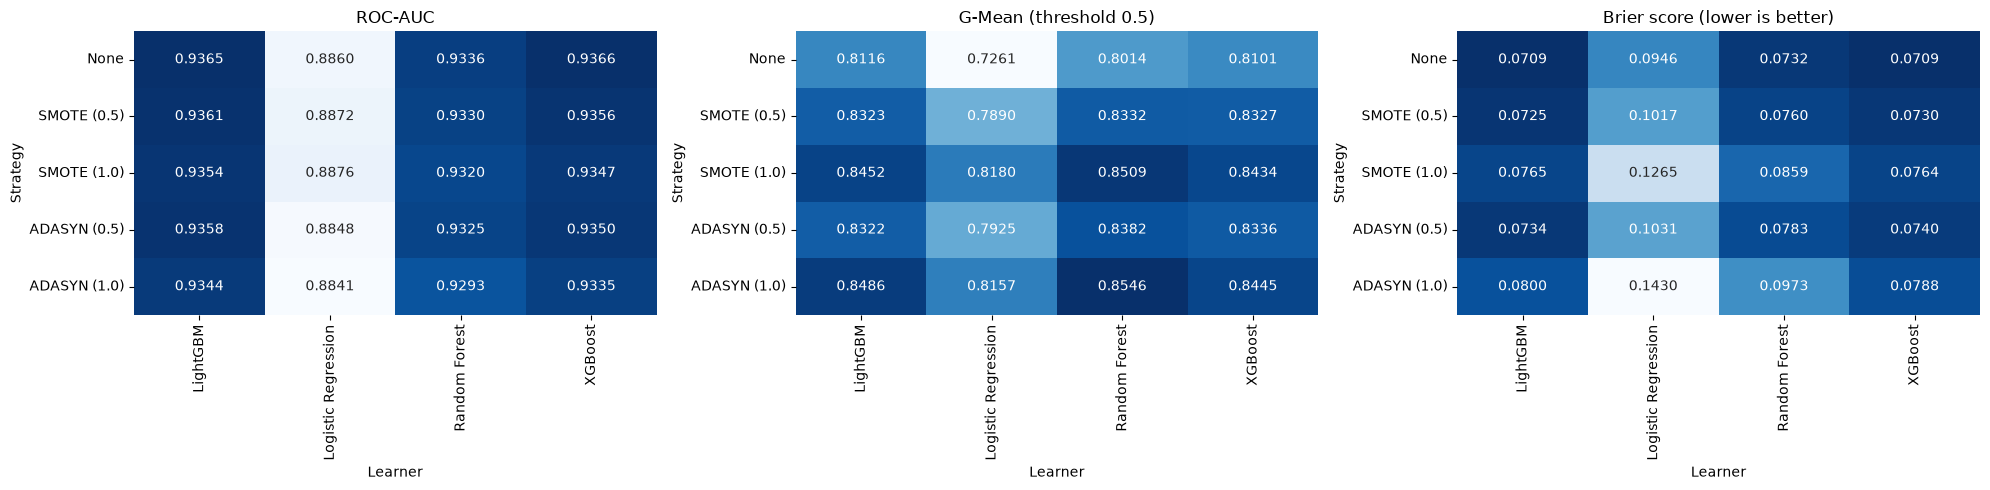

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (m, lab) in zip(axes, [("roc_auc", "ROC-AUC"), ("g_mean", "G-Mean (threshold 0.5)"), ("brier", "Brier score (lower is better)")]):
    pv = imb.pivot(index="Strategy", columns="Learner", values=f"{m} mean").loc[list(strategies)]
    sns.heatmap(pv, annot=True, fmt=".4f", cmap="Blues" if m != "brier" else "Blues_r", ax=ax, cbar=False)
    ax.set_title(lab)
plt.tight_layout()
plt.savefig(FIG_ABLATION / "imbalance_matrix_heatmap.png", bbox_inches="tight")
plt.show()

## 2. Fidelity of synthetic churners (SMOTE, ADASYN at ratio 1.0)

In [5]:
pre = make_preprocessor().fit(X_train)
feat = list(pre.get_feature_names_out())
Xp = pd.DataFrame(pre.transform(X_train), columns=feat)
scaler = pre.named_transformers_["num"]
n_real = len(Xp)
real_min = Xp[y_train.values == 1]


def to_original_units(df):
    out = df.copy()
    out[NUMERICAL_COLS] = scaler.inverse_transform(df[NUMERICAL_COLS])
    return out


synthetic = {}
for sname, smp in {"SMOTE": SMOTE(sampling_strategy=1.0, random_state=RANDOM_STATE),
                   "ADASYN": ADASYN(sampling_strategy=1.0, random_state=RANDOM_STATE)}.items():
    Xr, yr = smp.fit_resample(Xp, y_train.values)
    synthetic[sname] = pd.DataFrame(Xr[n_real:], columns=feat)   # imblearn appends synthetic rows

real_orig = to_original_units(real_min)
discrete = ["Tenure", "NumOfProducts", "HasCrCard", "IsActiveMember", "Geography_Germany", "Geography_Spain", "Gender_Male"]
fid_rows = []
for sname, S in synthetic.items():
    S_orig = to_original_units(S)
    row = {"Sampler": sname, "Synthetic samples": len(S)}
    for f in ["Age", "Balance", "CreditScore", "EstimatedSalary", "NumOfProducts", "Tenure"]:
        row[f"KS {f}"] = stats.ks_2samp(real_orig[f], S_orig[f]).statistic
    invalid = np.zeros(len(S), dtype=bool)
    for f in discrete:
        invalid |= ~np.isclose(S_orig[f], np.round(S_orig[f]), atol=1e-6)
    row["% rows with non-integer discrete values"] = invalid.mean() * 100
    row["% non-integer NumOfProducts"] = (~np.isclose(S_orig["NumOfProducts"], np.round(S_orig["NumOfProducts"]))).mean() * 100
    row["% non-integer Tenure"] = (~np.isclose(S_orig["Tenure"], np.round(S_orig["Tenure"]))).mean() * 100
    row["% non-binary HasCrCard / IsActiveMember"] = (~np.isin(np.round(S_orig[["HasCrCard", "IsActiveMember"]], 6), [0, 1]).all(axis=1)).mean() * 100
    row["% non-binary one-hot (Geography, Gender)"] = (~np.isin(np.round(S_orig[["Geography_Germany", "Geography_Spain", "Gender_Male"]], 6), [0, 1]).all(axis=1)).mean() * 100
    # classifier two-sample test: can a random forest tell real churners from synthetic ones?
    Z = pd.concat([real_min, S.sample(len(real_min), random_state=RANDOM_STATE, replace=len(S) < len(real_min))])
    lab = np.r_[np.zeros(len(real_min)), np.ones(len(real_min))]
    row["C2ST AUC (0.5 = indistinguishable)"] = cross_val_score(
        RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1), Z, lab,
        cv=tuning_cv(), scoring="roc_auc").mean()
    fid_rows.append(row)

# class overlap: share of majority-class customers among the 5 nearest real neighbours
nn = NearestNeighbors(n_neighbors=6).fit(Xp)
def majority_share(points, exclude_self):
    idx = nn.kneighbors(points, return_distance=False)
    idx = idx[:, 1:] if exclude_self else idx[:, :5]
    return (y_train.values[idx] == 0).mean()
overlap = {"Real churners": majority_share(real_min, True)}
overlap.update({s: majority_share(S, False) for s, S in synthetic.items()})

fidelity = pd.DataFrame(fid_rows).set_index("Sampler")
fidelity["Majority share among 5-NN"] = [overlap[s] for s in fidelity.index]
fidelity.to_csv(ABLATION_DIR / "synthetic_sample_fidelity.csv")
print(f"5-NN majority share of real churners (reference): {overlap['Real churners']:.3f}")
fidelity.drop(columns=["% rows with non-integer discrete values"]).round(3).T

5-NN majority share of real churners (reference): 0.390


Sampler,SMOTE,ADASYN
Synthetic samples,7108.000,6603.000
KS Age,0.048,0.254
KS Balance,0.033,0.031
KS CreditScore,0.036,0.056
KS EstimatedSalary,0.035,0.061
KS NumOfProducts,0.010,0.087
KS Tenure,0.064,0.078
% non-integer NumOfProducts,2.153,2.877
% non-integer Tenure,71.539,75.557
% non-binary HasCrCard / IsActiveMember,0.506,0.439


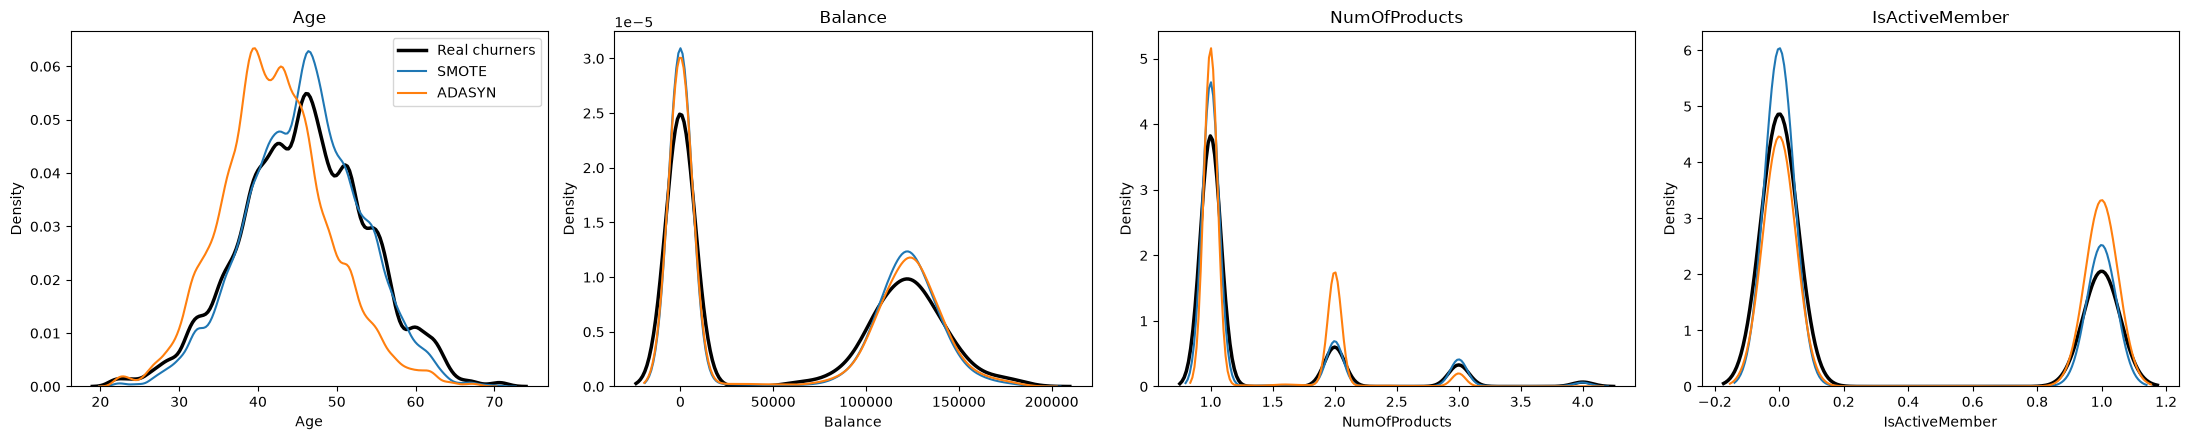

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, f in zip(axes, ["Age", "Balance", "NumOfProducts", "IsActiveMember"]):
    sns.kdeplot(real_orig[f], ax=ax, label="Real churners", lw=2.5, color="black", bw_adjust=0.6)
    for sname, S in synthetic.items():
        sns.kdeplot(to_original_units(S)[f], ax=ax, label=sname, lw=1.5, bw_adjust=0.6)
    ax.set_title(f)
axes[0].legend()
plt.tight_layout()
plt.savefig(FIG_ABLATION / "synthetic_sample_distributions.png", bbox_inches="tight")
plt.show()

## 3. Scalers, convergence and outliers

In [7]:
scalers = {"StandardScaler": StandardScaler(), "RobustScaler": RobustScaler(),
           "QuantileTransformer": QuantileTransformer(output_distribution="normal", random_state=RANDOM_STATE),
           "MinMaxScaler": MinMaxScaler()}
scale_learners = ["Logistic Regression (Baseline)", "SVM (RBF)", "KNN", "MLP"]
scale_rows = []
for lname in scale_learners:
    for sname, sc in scalers.items():
        pipe = build(lname, best_params[lname], preprocessor=make_preprocessor(clone(sc)))
        res = cross_validate(pipe, X_train, y_train, cv=tuning_cv(), scoring="roc_auc", n_jobs=N_SPLITS)
        # wall-clock time of one sequential fit on the whole training partition (median of 3)
        times = []
        for _ in range(3):
            t0 = time.perf_counter()
            fitted = clone(pipe).fit(X_train, y_train)
            times.append(time.perf_counter() - t0)
        n_iter = np.nan
        if lname in ("Logistic Regression (Baseline)", "MLP"):
            n_iter = int(np.max(fitted.named_steps["classifier"].n_iter_))
        scale_rows.append({"Learner": lname, "Scaler": sname, "CV ROC-AUC": res["test_score"].mean(),
                           "CV ROC-AUC std": res["test_score"].std(), "Fit time on train (s)": float(np.median(times)),
                           "Iterations to converge": n_iter})

# Tree model with and without scaling
for lname in ["XGBoost"]:
    for sname, pre_ in {"StandardScaler": make_preprocessor(), "No scaling": make_tpot_encoder()}.items():
        pipe = build(lname, best_params[lname], preprocessor=pre_)
        res = cross_validate(pipe, X_train, y_train, cv=tuning_cv(), scoring="roc_auc", n_jobs=N_SPLITS)
        t0 = time.perf_counter(); clone(pipe).fit(X_train, y_train); t_fit = time.perf_counter() - t0
        scale_rows.append({"Learner": lname, "Scaler": sname, "CV ROC-AUC": res["test_score"].mean(),
                           "CV ROC-AUC std": res["test_score"].std(), "Fit time on train (s)": t_fit,
                           "Iterations to converge": np.nan})
scaling = pd.DataFrame(scale_rows)
scaling.to_csv(ABLATION_DIR / "scaling_ablation.csv", index=False)
scaling.set_index(["Learner", "Scaler"]).round(4)

CV ROC-AUC 
 CV ROC-AUC std 
 Fit time on train (s) 
 Iterations to converge 
 
 
 Learner 
 Scaler 
 
 
 
 
 
 
 
 
 Logistic Regression (Baseline) 
 StandardScaler 
 0.8863 
 0.0081 
 0.0799 
 14.0 
 
 
 RobustScaler 
 0.8863 
 0.0081 
 0.0697 
 12.0 
 
 
 QuantileTransformer 
 0.9003 
 0.0062 
 0.0904 
 47.0 
 
 
 MinMaxScaler 
 0.8860 
 0.0080 
 0.0388 
 20.0 
 
 
 SVM (RBF) 
 StandardScaler 
 0.9226 
 0.0039 
 1.2401 
 NaN 
 
 
 RobustScaler 
 0.9002 
 0.0071 
 1.1584 
 NaN 
 
 
 QuantileTransformer 
 0.9029 
 0.0030 
 1.3078 
 NaN 
 
 
 MinMaxScaler 
 0.8842 
 0.0085 
 1.1978 
 NaN 
 
 
 KNN 
 StandardScaler 
 0.9192 
 0.0034 
 0.0203 
 NaN 
 
 
 RobustScaler 
 0.9204 
 0.0042 
 0.0227 
 NaN 
 
 
 QuantileTransformer 
 0.9101 
 0.0031 
 0.0366 
 NaN 
 
 
 MinMaxScaler 
 0.8970 
 0.0040 
 0.0190 
 NaN 
 
 
 MLP 
 StandardScaler 
 0.9326 
 0.0035 
 0.7235 
 31.0 
 
 
 RobustScaler 
 0.9332 
 0.0033 
 0.6422 
 31.0 
 
 
 QuantileTransformer 
 0.9299 
 0.0018 
 0.5584 
 27.0 
 
 
 MinMaxScaler 
 0.9305 
 0.0030 
 1.1823 
 57.0 
 
 
 XGBoost 
 StandardScaler 
 0.9369 
 0.0052 
 0.3673 
 NaN 
 
 
 No scaling 
 0.9369 
 0.0052 
 0.3248 
 NaN

In [8]:
def drop_outliers(Xf, yf, z=3.0):
    """Remove training-fold rows with |z| > 3 on continuous predictors (statistics of the fold only)."""
    Xf = pd.DataFrame(Xf)
    cols = ["Age", "Balance", "CreditScore", "EstimatedSalary"]
    zs = np.abs((Xf[cols] - Xf[cols].mean()) / Xf[cols].std())
    keep = (zs < z).all(axis=1).values
    return Xf[keep], np.asarray(yf)[keep]


out_rows = []
for lname in ["Logistic Regression (Baseline)", "MLP", "XGBoost", "LightGBM"]:
    base = build(lname, best_params[lname])
    for oname, pipe in {"Keep outliers": base,
                        "Remove |z|>3 in training folds": with_sampler(base, FunctionSampler(func=drop_outliers, validate=False),
                                                                       before_preprocessing=True)}.items():
        d = rcv_scores(pipe)
        out_rows.append({"Learner": lname, "Outliers": oname, "_scores": d})
outl = []
for r in out_rows:
    ref = next(o["_scores"] for o in out_rows if o["Learner"] == r["Learner"] and o["Outliers"] == "Keep outliers")
    d = r["_scores"]
    outl.append({"Learner": r["Learner"], "Outliers": r["Outliers"],
                 "CV ROC-AUC": f"{d.roc_auc.mean():.4f} ± {d.roc_auc.std():.4f}",
                 "CV G-Mean": f"{d.g_mean.mean():.4f} ± {d.g_mean.std():.4f}",
                 "p AUC vs keep (corr. t)": np.nan if r["Outliers"] == "Keep outliers"
                 else corrected_resampled_ttest(d.roc_auc, ref.roc_auc, N_TRAIN_FOLD, N_VAL_FOLD)[1]})
outliers_df = pd.DataFrame(outl)
outliers_df.to_csv(ABLATION_DIR / "outlier_ablation.csv", index=False)
outliers_df.set_index(["Learner", "Outliers"]).round(4)

CV ROC-AUC 
 CV G-Mean 
 p AUC vs keep (corr. t) 
 
 
 Learner 
 Outliers 
 
 
 
 
 
 
 
 Logistic Regression (Baseline) 
 Keep outliers 
 0.8860 ± 0.0075 
 0.7261 ± 0.0135 
 NaN 
 
 
 Remove |z|>3 in training folds 
 0.8875 ± 0.0072 
 0.7438 ± 0.0119 
 0.0089 
 
 
 MLP 
 Keep outliers 
 0.9317 ± 0.0052 
 0.8078 ± 0.0166 
 NaN 
 
 
 Remove |z|>3 in training folds 
 0.9293 ± 0.0050 
 0.8028 ± 0.0155 
 0.0912 
 
 
 XGBoost 
 Keep outliers 
 0.9366 ± 0.0052 
 0.8101 ± 0.0122 
 NaN 
 
 
 Remove |z|>3 in training folds 
 0.9358 ± 0.0051 
 0.8106 ± 0.0121 
 0.0012 
 
 
 LightGBM 
 Keep outliers 
 0.9365 ± 0.0053 
 0.8116 ± 0.0125 
 NaN 
 
 
 Remove |z|>3 in training folds 
 0.9356 ± 0.0053 
 0.8124 ± 0.0122 
 0.0014

## 4. Feature engineering and pruning

In [9]:
pruned_num = [c for c in NUMERICAL_COLS if c not in ("HasCrCard", "Tenure", "CreditScore", "EstimatedSalary")]
def pruned_preprocessor():
    return ColumnTransformer([("num", StandardScaler(), pruned_num),
                              ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"),
                               CATEGORICAL_COLS)], remainder="drop", verbose_feature_names_out=False)

feature_sets = {"Raw": make_preprocessor, "Raw + engineered": make_fe_preprocessor, "Pruned": pruned_preprocessor}
fe_learners = ["Logistic Regression (Baseline)", "XGBoost", "LightGBM", "CatBoost"]
fe_scores = {}
for lname in fe_learners:
    for fname, pre_fn in feature_sets.items():
        fe_scores[(lname, fname)] = rcv_scores(build(lname, best_params[lname], preprocessor=pre_fn()))

fe_rows = []
for (lname, fname), d in fe_scores.items():
    ref = fe_scores[(lname, "Raw")]
    t, p = (np.nan, np.nan) if fname == "Raw" else corrected_resampled_ttest(d.roc_auc, ref.roc_auc, N_TRAIN_FOLD, N_VAL_FOLD)
    fe_rows.append({"Learner": lname, "Feature set": fname,
                    "CV ROC-AUC": f"{d.roc_auc.mean():.4f} ± {d.roc_auc.std():.4f}",
                    "CV G-Mean": f"{d.g_mean.mean():.4f} ± {d.g_mean.std():.4f}",
                    "Mean ΔAUC vs Raw": d.roc_auc.mean() - ref.roc_auc.mean(), "p vs Raw (corr. t)": p})
fe_df = pd.DataFrame(fe_rows)
fe_df["p vs Raw (Holm)"] = np.nan
mask = fe_df["Feature set"] != "Raw"
fe_df.loc[mask, "p vs Raw (Holm)"] = holm_correction(fe_df.loc[mask, "p vs Raw (corr. t)"].values)
fe_df.to_csv(ABLATION_DIR / "feature_ablation.csv", index=False)
fe_df.set_index(["Learner", "Feature set"]).round(4)

CV ROC-AUC 
 CV G-Mean 
 Mean ΔAUC vs Raw 
 p vs Raw (corr. t) 
 p vs Raw (Holm) 
 
 
 Learner 
 Feature set 
 
 
 
 
 
 
 
 
 
 Logistic Regression (Baseline) 
 Raw 
 0.8860 ± 0.0075 
 0.7261 ± 0.0135 
 0.0000 
 NaN 
 NaN 
 
 
 Raw + engineered 
 0.8862 ± 0.0076 
 0.7317 ± 0.0124 
 0.0002 
 0.7343 
 1.0000 
 
 
 Pruned 
 0.8854 ± 0.0074 
 0.7252 ± 0.0147 
 -0.0006 
 0.1252 
 0.8761 
 
 
 XGBoost 
 Raw 
 0.9366 ± 0.0052 
 0.8101 ± 0.0122 
 0.0000 
 NaN 
 NaN 
 
 
 Raw + engineered 
 0.9363 ± 0.0053 
 0.8099 ± 0.0117 
 -0.0003 
 0.2748 
 1.0000 
 
 
 Pruned 
 0.9365 ± 0.0050 
 0.8117 ± 0.0124 
 -0.0000 
 0.9333 
 1.0000 
 
 
 LightGBM 
 Raw 
 0.9365 ± 0.0053 
 0.8116 ± 0.0125 
 0.0000 
 NaN 
 NaN 
 
 
 Raw + engineered 
 0.9359 ± 0.0054 
 0.8108 ± 0.0123 
 -0.0005 
 0.0813 
 0.6507 
 
 
 Pruned 
 0.9362 ± 0.0051 
 0.8106 ± 0.0127 
 -0.0003 
 0.5043 
 1.0000 
 
 
 CatBoost 
 Raw 
 0.9368 ± 0.0054 
 0.8074 ± 0.0128 
 0.0000 
 NaN 
 NaN 
 
 
 Raw + engineered 
 0.9367 ± 0.0053 
 0.8060 ± 0.0136 
 -0.0001 
 0.7990 
 1.0000 
 
 
 Pruned 
 0.9369 ± 0.0050 
 0.8099 ± 0.0127 
 0.0001 
 0.8194 
 1.0000